In [7]:
import pandas as pd

# Load the datasets from the root folder
appointments = pd.read_csv('/apollo_appointments_fact.csv')
doctors = pd.read_csv('/apollo_doctors_dim.csv')

# Verify the data loaded correctly
print(f"Appointments data loaded: {appointments.shape[0]} rows and {appointments.shape[1]} columns")
print(f"Doctors data loaded: {doctors.shape[0]} rows and {doctors.shape[1]} columns")

Appointments data loaded: 75000 rows and 52 columns
Doctors data loaded: 320 rows and 15 columns


## 1. Business Overview

--- APPOINTMENT OUTCOMES ---
Completed: 55,275 (73.7%)
No-Show: 11,584 (15.4%)
Cancelled: 5,793 (7.7%)
Scheduled: 2,348 (3.1%)

--- BOOKING CHANNELS ---
booking_channel
Apollo App     34042
Website        18545
Call Centre    11201
Walk-In         7501
Partner App     3711

--- MONTHLY TREND CHART ---


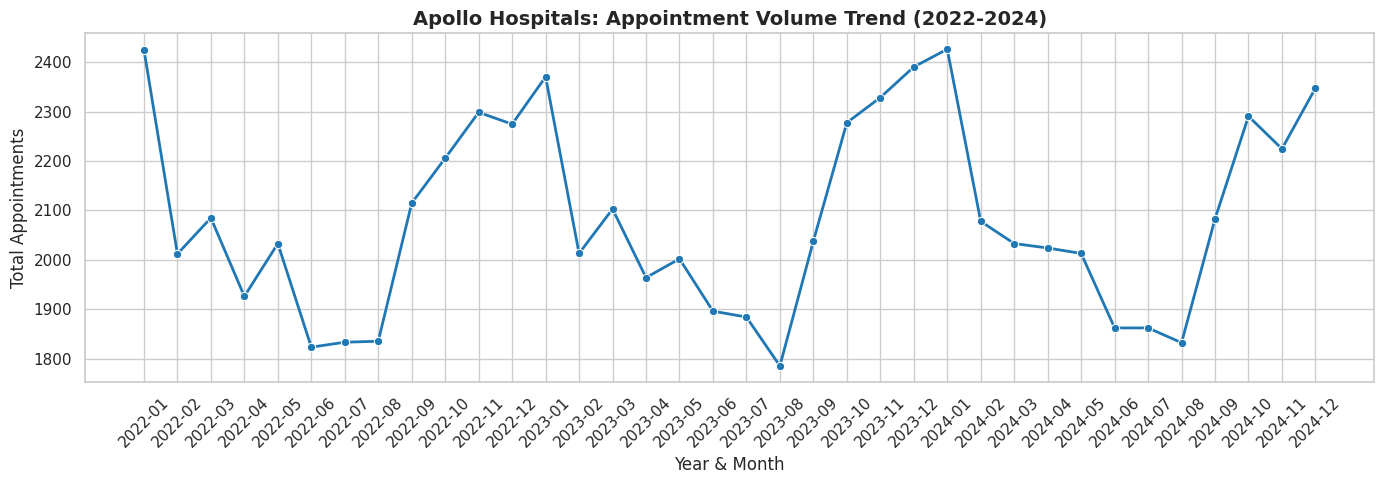

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional style for our charts
sns.set_theme(style="whitegrid")

# 1. Split of Appointment Outcomes
print("--- APPOINTMENT OUTCOMES ---")
# Python will automatically find the column related to 'status'
status_col = [c for c in appointments.columns if 'status' in c.lower()][0]
status_counts = appointments[status_col].value_counts()
status_percentages = appointments[status_col].value_counts(normalize=True) * 100
for status, count in status_counts.items():
    print(f"{status}: {count:,} ({status_percentages[status]:.1f}%)")

# 2. Booking Channel Mix
print("\n--- BOOKING CHANNELS ---")
# Python will automatically find the column related to 'channel'
channel_col = [c for c in appointments.columns if 'channel' in c.lower()][0]
channel_counts = appointments[channel_col].value_counts()
print(channel_counts.to_string())

# 3. Monthly Volume Trend Chart
print("\n--- MONTHLY TREND CHART ---")
plt.figure(figsize=(14, 5))
# Group the data by Year and Month
monthly_volume = appointments.groupby(['appointment_year', 'appointment_month']).size().reset_index(name='Volume')
monthly_volume['Period'] = monthly_volume['appointment_year'].astype(str) + "-" + monthly_volume['appointment_month'].astype(str).str.zfill(2)

# Draw the line chart
sns.lineplot(data=monthly_volume, x='Period', y='Volume', marker='o', color='#1f77b4', linewidth=2)
plt.xticks(rotation=45)
plt.title('Apollo Hospitals: Appointment Volume Trend (2022-2024)', fontsize=14, fontweight='bold')
plt.ylabel('Total Appointments')
plt.xlabel('Year & Month')
plt.tight_layout()
plt.show()

## 2. No-Show Analysis

--- 1. SPECIALTY & CITY NO-SHOW RATES ---
Highest Specialty Risk: Psychiatry (24.5%) | Lowest: Neurology (10.7%)
Highest City Risk: Lucknow (17.2%) | Lowest: Pune (13.3%)

--- 2. TIME & DAY DROPOUT RISK ---
Weekend No-Show Rate: nan% vs Weekday Rate: 15.9%
Evening Slot No-Show Rate: 18.4% vs Morning Rate: 13.7%

--- 3. RISK BY APPOINTMENT TYPE ---
appointment_type
Home Visit       26.2%
In-Clinic        12.2%
Video Consult    21.1%


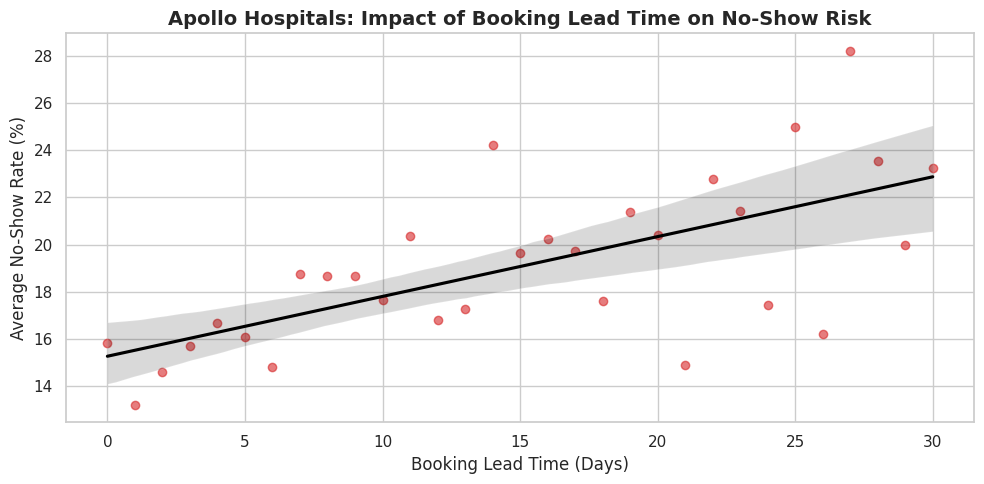

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Apply the rubric rule: Exclude 'Scheduled' to calculate true no-show rates
df_valid = appointments[appointments['appointment_status'] != 'Scheduled'].copy()
# Create a percentage flag for easy averaging
df_valid['ns_rate'] = (df_valid['appointment_status'] == 'No-Show').astype(int) * 100

print("--- 1. SPECIALTY & CITY NO-SHOW RATES ---")
spec_rates = df_valid.groupby('specialty')['ns_rate'].mean().sort_values(ascending=False)
city_rates = df_valid.groupby('city')['ns_rate'].mean().sort_values(ascending=False)
print(f"Highest Specialty Risk: {spec_rates.index[0]} ({spec_rates.iloc[0]:.1f}%) | Lowest: {spec_rates.index[-1]} ({spec_rates.iloc[-1]:.1f}%)")
print(f"Highest City Risk: {city_rates.index[0]} ({city_rates.iloc[0]:.1f}%) | Lowest: {city_rates.index[-1]} ({city_rates.iloc[-1]:.1f}%)")

print("\n--- 2. TIME & DAY DROPOUT RISK ---")
weekend_rate = df_valid[df_valid['appointment_day_of_week'].isin(['Saturday', 'Sunday'])]['ns_rate'].mean()
weekday_rate = df_valid[~df_valid['appointment_day_of_week'].isin(['Saturday', 'Sunday'])]['ns_rate'].mean()
print(f"Weekend No-Show Rate: {weekend_rate:.1f}% vs Weekday Rate: {weekday_rate:.1f}%")

evening_rate = df_valid[df_valid['time_of_day'] == 'Evening']['ns_rate'].mean()
morning_rate = df_valid[df_valid['time_of_day'] == 'Morning']['ns_rate'].mean()
print(f"Evening Slot No-Show Rate: {evening_rate:.1f}% vs Morning Rate: {morning_rate:.1f}%")

print("\n--- 3. RISK BY APPOINTMENT TYPE ---")
print(df_valid.groupby('appointment_type')['ns_rate'].mean().apply(lambda x: f"{x:.1f}%").to_string())

# 4. Visualizing No-Show Risk by Lead Time
plt.figure(figsize=(10, 5))
lead_time_df = df_valid.groupby('booking_lead_days')['ns_rate'].mean().reset_index()
sns.regplot(data=lead_time_df, x='booking_lead_days', y='ns_rate',
            scatter_kws={'alpha':0.6, 'color':'#d62728'}, line_kws={'color':'black'})
plt.title('Apollo Hospitals: Impact of Booking Lead Time on No-Show Risk', fontsize=14, fontweight='bold')
plt.xlabel('Booking Lead Time (Days)')
plt.ylabel('Average No-Show Rate (%)')
plt.tight_layout()
plt.show()

## 3. Reminder and Engagement Effectiveness

--- 1. REMINDER EFFECTIVENESS ---
reminder_type
SMS + WhatsApp + Call    11.4%
SMS + WhatsApp           13.5%
SMS Only                 16.3%
No Reminder              30.2%

--- 2. PRIOR NO-SHOW HISTORY ---
prior_noshow_category
0 Prior     15.2%
1 Prior     20.3%
2+ Prior    27.5%

--- 3. MEMBERSHIP & LOYALTY ---
Apollo Member No-Show Rate: 12.7% | Non-Member: 16.9%
Repeat Patient No-Show Rate: 8.6% | First-Time Patient: 66.8%


/tmp/ipykernel_606/1197140130.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=reminder_rates.index, y=reminder_rates.values, palette='viridis')


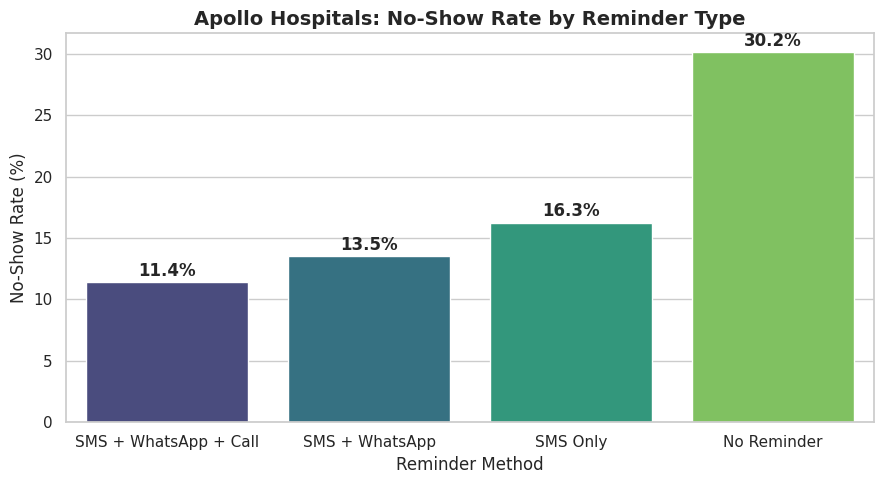

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- 1. REMINDER EFFECTIVENESS ---")
reminder_rates = df_valid.groupby('reminder_type')['ns_rate'].mean().sort_values()
print(reminder_rates.apply(lambda x: f"{x:.1f}%").to_string())

print("\n--- 2. PRIOR NO-SHOW HISTORY ---")
# Group patients by how many times they have no-showed before (0, 1, or 2+)
df_valid['prior_noshow_category'] = np.where(df_valid['patient_prior_no_shows'] >= 2, '2+ Prior',
                                     np.where(df_valid['patient_prior_no_shows'] == 1, '1 Prior', '0 Prior'))
history_rates = df_valid.groupby('prior_noshow_category')['ns_rate'].mean()
print(history_rates.apply(lambda x: f"{x:.1f}%").to_string())

print("\n--- 3. MEMBERSHIP & LOYALTY ---")
member_rate = df_valid.groupby('apollo_member')['ns_rate'].mean()
print(f"Apollo Member No-Show Rate: {member_rate['Yes']:.1f}% | Non-Member: {member_rate['No']:.1f}%")

repeat_rate = df_valid.groupby('repeat_visit')['ns_rate'].mean()
print(f"Repeat Patient No-Show Rate: {repeat_rate['Yes']:.1f}% | First-Time Patient: {repeat_rate['No']:.1f}%")

# 4. Visualizing Reminder Effectiveness
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=reminder_rates.index, y=reminder_rates.values, palette='viridis')
plt.title('Apollo Hospitals: No-Show Rate by Reminder Type', fontsize=14, fontweight='bold')
plt.ylabel('No-Show Rate (%)')
plt.xlabel('Reminder Method')

# Add the exact percentages on top of the bars for maximum professionalism
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Patient and Demographic Segmentation

--- 1. DEMOGRAPHIC NO-SHOW RISKS ---
By Gender:
patient_gender
Female    16.0%
Male      15.8%

By Age Group:
age_group
Adult (31-45)          18.0%
Child (0-12)           13.5%
Middle-aged (46-60)    16.8%
Senior (60+)           14.0%
Teen (13-18)           14.7%
Young Adult (19-30)    17.9%

By Chronic Condition:
patient_chronic_condition
Asthma            16.7%
Diabetes          15.8%
Heart Disease     16.3%
Hypertension      15.6%
Hypothyroidism    15.5%

--- 2. VISIT REASON DROPOUT RISK ---
                              Total_Visits No_Show_Rate
visit_reason                                           
Follow-up                             8528        15.2%
Routine Checkup                       8377        15.6%
Chronic Condition Management          8117        15.6%
Digestive Problem                     7984        16.2%
Fever & Infection                     6808        16.1%

--- 3. AGE DISTRIBUTION IN KEY SPECIALTIES ---


/tmp/ipykernel_606/4197646858.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=spec_dist_df, x='specialty', y='patient_age', palette='Set2')


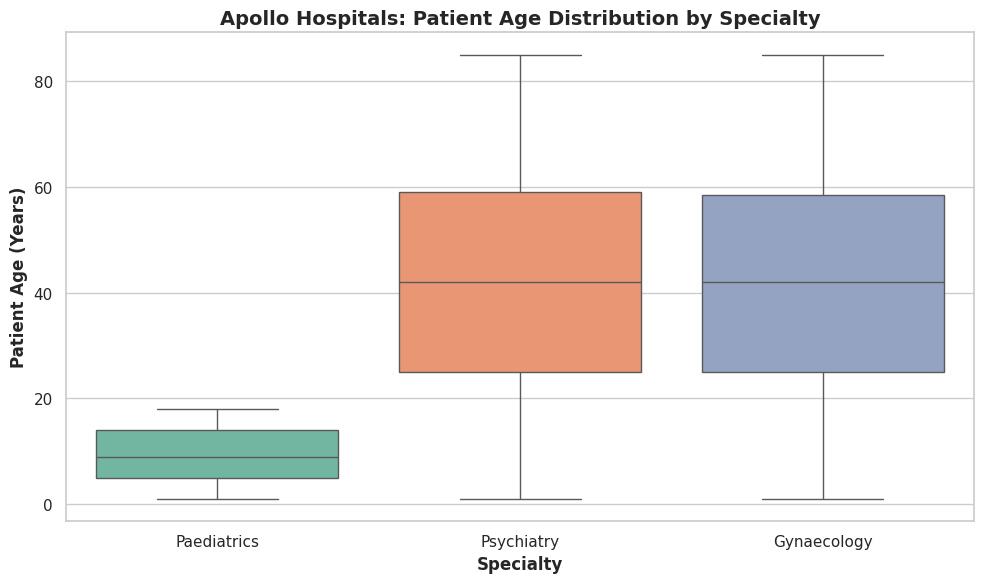

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. DEMOGRAPHIC NO-SHOW RISKS ---")
# Gender
gender_rate = df_valid.groupby('patient_gender')['ns_rate'].mean()
print("By Gender:")
print(gender_rate.apply(lambda x: f"{x:.1f}%").to_string())

# Age Group
print("\nBy Age Group:")
age_rate = df_valid.groupby('age_group')['ns_rate'].mean()
print(age_rate.apply(lambda x: f"{x:.1f}%").to_string())

# Chronic Condition
print("\nBy Chronic Condition:")
# The rubric explicitly states 'None' is not missing data, but indicates no condition
chronic_df = df_valid[df_valid['patient_chronic_condition'] != 'None']
chronic_rate = chronic_df.groupby('patient_chronic_condition')['ns_rate'].mean()
print(chronic_rate.apply(lambda x: f"{x:.1f}%").to_string())

print("\n--- 2. VISIT REASON DROPOUT RISK ---")
visit_reason_stats = df_valid.groupby('visit_reason').agg(
    Total_Visits=('appointment_id', 'count'),
    No_Show_Rate=('ns_rate', 'mean')
).sort_values('Total_Visits', ascending=False).head(5)
visit_reason_stats['No_Show_Rate'] = visit_reason_stats['No_Show_Rate'].apply(lambda x: f"{x:.1f}%")
print(visit_reason_stats.to_string())

print("\n--- 3. AGE DISTRIBUTION IN KEY SPECIALTIES ---")
# Filter for the specific specialties requested in the rubric
target_specialties = ['Paediatrics', 'Gynaecology', 'Psychiatry']
spec_dist_df = df_valid[df_valid['specialty'].isin(target_specialties)]

# Create a professional boxplot to show age distribution
plt.figure(figsize=(10, 6))
sns.boxplot(data=spec_dist_df, x='specialty', y='patient_age', palette='Set2')
plt.title('Apollo Hospitals: Patient Age Distribution by Specialty', fontsize=14, fontweight='bold')
plt.xlabel('Specialty', fontweight='bold')
plt.ylabel('Patient Age (Years)', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Financial Performance

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. REVENUE LOST TO NO-SHOWS ---")
# To find lost revenue, we calculate what the fee would have been (base fee minus discount)
df_noshow = appointments[appointments['appointment_status'] == 'No-Show'].copy()
df_noshow['expected_revenue'] = df_noshow['consultation_fee'] * (1 - df_noshow['discount_pct'] / 100)
total_lost = df_noshow['expected_revenue'].sum()
print(f"Total Estimated Revenue Lost to No-Shows: ₹{total_lost:,.0f}")

print("\n--- 2. REVENUE BY SPECIALTY & TYPE (COMPLETED ONLY) ---")
# Apply rubric rule: Only analyze Completed appointments for actual revenue
df_completed = appointments[appointments['appointment_status'] == 'Completed']

avg_rev_spec = df_completed.groupby('specialty')['revenue_realized'].mean().sort_values(ascending=False).head(5)
print("Top 5 Specialties by Avg Revenue:")
print(avg_rev_spec.apply(lambda x: f"₹{x:,.0f}").to_string())

avg_rev_type = df_completed.groupby('appointment_type')['revenue_realized'].mean().sort_values(ascending=False)
print("\nAvg Revenue by Appointment Type:")
print(avg_rev_type.apply(lambda x: f"₹{x:,.0f}").to_string())

print("\n--- 3. TOP CITIES & PAYMENT MIX ---")
city_rev = df_completed.groupby('city')['revenue_realized'].sum().sort_values(ascending=False).head(3)
print("Top 3 Cities by Total Revenue:")
print(city_rev.apply(lambda x: f"₹{x:,.0f}").to_string())

payment_mix = df_completed['payment_mode'].value_counts(normalize=True) * 100
print("\nPayment Mode Mix:")
print(payment_mix.apply(lambda x: f"{x:.1f}%").to_string())

print("\n--- 4. INSURANCE IMPACT ON OUT-OF-POCKET ---")
insurance_impact = df_completed.groupby('insurance_coverage')['patient_out_of_pocket'].mean()
print(f"Avg Out-of-Pocket (Insured): ₹{insurance_impact['Yes']:,.0f}")
print(f"Avg Out-of-Pocket (Uninsured): ₹{insurance_impact['No']:,.0f}")

--- 1. REVENUE LOST TO NO-SHOWS ---
Total Estimated Revenue Lost to No-Shows: ₹19,725,460

--- 2. REVENUE BY SPECIALTY & TYPE (COMPLETED ONLY) ---
Top 5 Specialties by Avg Revenue:
specialty
Psychiatry          ₹2,640
Neurology           ₹2,076
Urology             ₹1,989
Cardiology          ₹1,941
Gastroenterology    ₹1,897

Avg Revenue by Appointment Type:
appointment_type
Home Visit       ₹1,960
In-Clinic        ₹1,300
Video Consult    ₹1,098

--- 3. TOP CITIES & PAYMENT MIX ---
Top 3 Cities by Total Revenue:
city
Bengaluru    ₹9,990,616
Delhi        ₹9,958,247
Mumbai       ₹8,989,613

Payment Mode Mix:
payment_mode
Insurance      21.1%
Debit Card     13.3%
Net Banking    13.3%
Apollo Pay     13.3%
UPI            13.1%
Credit Card    13.0%
Cash           12.9%

--- 4. INSURANCE IMPACT ON OUT-OF-POCKET ---
Avg Out-of-Pocket (Insured): ₹859
Avg Out-of-Pocket (Uninsured): ₹1,563


## 6. Doctor Utilisation and Service Quality

--- 1. DOCTOR UTILISATION RATES ---
Highest Utilisation: Gastroenterology (77.3%)
Lowest Utilisation: Psychiatry (76.2%)

--- 2. WAIT TIMES BY SPECIALTY ---
Highest Average Wait Times:
specialty_x
Ophthalmology    12.0 mins
Urology          11.9 mins
Dermatology      11.8 mins


/tmp/ipykernel_606/306747526.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=merged_df, x='experience_group', y='consultation_fee_y', palette='Blues')


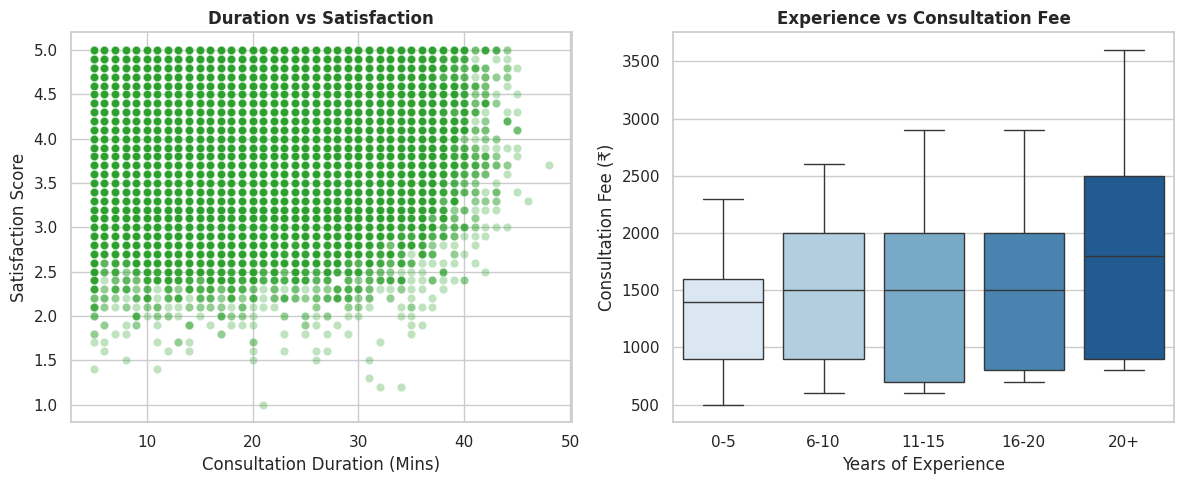

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Merge the appointments fact table with the doctors dimension table
df_completed = appointments[appointments['appointment_status'] == 'Completed']
merged_df = pd.merge(df_completed, doctors, on='doctor_id')

print("--- 1. DOCTOR UTILISATION RATES ---")
util_rates = merged_df.groupby('specialty_x')['doctor_utilization_pct'].mean().sort_values(ascending=False)
print(f"Highest Utilisation: {util_rates.index[0]} ({util_rates.iloc[0]:.1f}%)")
print(f"Lowest Utilisation: {util_rates.index[-1]} ({util_rates.iloc[-1]:.1f}%)")

print("\n--- 2. WAIT TIMES BY SPECIALTY ---")
wait_times = merged_df.groupby('specialty_x')['wait_time_minutes'].mean().sort_values(ascending=False).head(3)
print("Highest Average Wait Times:")
print(wait_times.apply(lambda x: f"{x:.1f} mins").to_string())

# 3. Scatter Plot: Consultation Duration vs Satisfaction Score
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=merged_df, x='consultation_duration_min', y='patient_satisfaction_score', alpha=0.3, color='#2ca02c')
plt.title('Duration vs Satisfaction', fontweight='bold')
plt.xlabel('Consultation Duration (Mins)')
plt.ylabel('Satisfaction Score')

# 4. Box Plot: Doctor Experience vs Consultation Fee
plt.subplot(1, 2, 2)
# Create bins for experience years to make the chart readable
merged_df['experience_group'] = pd.cut(merged_df['experience_years'], bins=[0, 5, 10, 15, 20, 30], labels=['0-5', '6-10', '11-15', '16-20', '20+'])
sns.boxplot(data=merged_df, x='experience_group', y='consultation_fee_y', palette='Blues')
plt.title('Experience vs Consultation Fee', fontweight='bold')
plt.xlabel('Years of Experience')
plt.ylabel('Consultation Fee (₹)')

plt.tight_layout()
plt.show()